# SMS Spam & Phishing Detector

Classify English SMS as `ham` or `spam`, and measure how much regex fingerprint features add on top of a bag-of-words model. Specs: `docs/project-specs.md`.

## 0. Setup

Imports and the fixed random seed used everywhere (NFR-1).

In [1]:
import numpy as np
import pandas as pd

RANDOM_STATE = 42
DATA_PATH = "data/spam.csv"

pd.set_option("display.max_colwidth", 120)

Download the NLTK data used below once (tokenizer, stopwords, WordNet, POS tagger). Already-present packages are skipped.

In [2]:
import nltk

for package in ["punkt_tab", "stopwords", "wordnet", "averaged_perceptron_tagger_eng"]:
    nltk.download(package, quiet=True)

## 1. Load and deduplicate (FR-1)

Read the CSV with `latin-1` (its real encoding), keep only the label and text columns, and add a numeric target `y`.

In [3]:
raw = pd.read_csv(DATA_PATH, encoding="latin-1")
print("Raw shape:", raw.shape)
print("Columns:", list(raw.columns))

df = raw[["v1", "v2"]].rename(columns={"v1": "label", "v2": "text"})
df["y"] = (df["label"] == "spam").astype(int)
df.head()

Raw shape: (5572, 5)
Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,label,text,y
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives around here though",0


A message that appeared with both labels would be contradictory training data; this check documents that the dataset has none.

In [4]:
labels_per_text = df.groupby(df["text"].str.strip())["label"].nunique()
assert (labels_per_text == 1).all(), "Some texts appear with both labels"
print("No message has conflicting labels.")

No message has conflicting labels.


Drop duplicates before any split so the same message never lands in both train and test. Duplicates are compared on trimmed text, but the `text` column itself stays raw for the regex branch.

In [5]:
n_before = len(df)
df = (df.loc[~df["text"].str.strip().duplicated(keep="first")]
        .reset_index(drop=True))

print(f"Rows before: {n_before}, after: {len(df)}, removed: {n_before - len(df)}")
print("\nClass balance after deduplication:")
print(df["label"].value_counts().to_frame("count")
        .assign(share=lambda t: (t["count"] / t["count"].sum()).round(3)))

Rows before: 5572, after: 5158, removed: 414

Class balance after deduplication:
       count  share
label              
ham     4516  0.876
spam     642  0.124


## 2. Regex fingerprint features (FR-2)

Patterns live in `features.py` so the notebook and the Streamlit app compute exactly the same features. They run on the raw `text`, before cleaning, because cleaning removes links, numbers and CAPS.

In [6]:
from features import FEATURES, FINGERPRINTS, FEATURE_NAMES, regex_features

for name, pattern in FEATURES.items():
    print(f"{name:13s} {pattern}")

n_urls        https?://\S+|www\.\S+|\b\w+\.(?:com|net|org|co\.uk)\b
n_phones      \+?\d[\d\s-]{8,}\d
n_shortcodes  \b\d{5}\b
n_money       [£$€]\s?\d+|\b\d+\s?(?:p|pounds?)\b
n_caps        \b[A-Z]{2,}\b
n_urgent      (?i)\b(?:free|win|winner|won|claim|prize|urgent|txt|reply|stop|call now)\b
n_exclaim     !


Apply the extractor to every message and add one column per feature to `df`.

In [7]:
feats = pd.DataFrame(df["text"].map(regex_features).tolist(), index=df.index)
df = pd.concat([df, feats], axis=1)
df[["label", "text"] + FEATURE_NAMES].head()

,label,text,n_urls,n_phones,n_shortcodes,n_money,n_caps,n_urgent,n_exclaim,n_chars,n_words,digit_ratio
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0,0,0,0,0,0,0,111,20,0.00000
1,ham,Ok lar... Joking wif u oni...,0,0,0,0,0,0,0,29,6,0.00000
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,0,1,1,0,2,3,0,155,28,0.16129
3,ham,U dun say so early hor... U c already then say...,0,0,0,0,0,0,0,49,11,0.00000
4,ham,"Nah I don't think he goes to usf, he lives around here though",0,0,0,0,0,0,0,61,13,0.00000


Sanity check on a typical spam message: each pattern should catch only what it is meant to.

In [8]:
example = "Call 08712300220 or text WIN to 87121"
regex_features(example)

{'n_urls': 0,
 'n_phones': 1,
 'n_shortcodes': 1,
 'n_money': 0,
 'n_caps': 1,
 'n_urgent': 1,
 'n_exclaim': 0,
 'n_chars': 37,
 'n_words': 7,
 'digit_ratio': 0.43243243243243246}

Share of messages where each fingerprint fires at least once, per class. A useful fingerprint fires often in spam and rarely in ham.

In [9]:
hit_rate = (df[FINGERPRINTS] > 0).groupby(df["label"]).mean().T.round(3)
hit_rate["spam / ham"] = (hit_rate["spam"] / hit_rate["ham"].replace(0, np.nan)).round(1)
hit_rate

label,ham,spam,spam / ham
n_urls,0.002,0.178,89.0
n_phones,0.000,0.576,NaN
n_shortcodes,0.000,0.316,NaN
n_money,0.003,0.498,166.0
n_caps,0.070,0.727,10.4
n_urgent,0.036,0.684,19.0
n_exclaim,0.117,0.469,4.0


Mean value of every feature per class, including length and digit ratio.

In [10]:
df.groupby("label")[FEATURE_NAMES].mean().T.round(3)

label,ham,spam
n_urls,0.002,0.187
n_phones,0.000,0.625
n_shortcodes,0.000,0.341
n_money,0.004,0.639
n_caps,0.381,1.983
n_urgent,0.039,1.389
n_exclaim,0.175,0.688
n_chars,70.459,137.629
n_words,14.135,23.640
digit_ratio,0.004,0.114


## 3. Train/test split

80/20, stratified on `y` so both parts keep the same spam share, with the fixed seed. The test set is used only once, for the final results table.

In [11]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=RANDOM_STATE)

for name, part in [("train", train), ("test", test)]:
    print(f"{name:5s} rows={len(part):5d}  spam share={part['y'].mean():.3f}")

train rows= 4126  spam share=0.125
test  rows= 1032  spam share=0.124


## 4. Model 0: regex rules, no machine learning

Rule: a message is spam if at least `k` **different** fingerprints fire. Counting distinct patterns (not total matches) stops one repeated signal, like a message in all caps, from triggering the rule on its own.

In [12]:
def n_fingerprints(features: pd.DataFrame) -> pd.Series:
    """Number of distinct regex fingerprints (0-7) that fired in each message."""
    return (features[FINGERPRINTS] > 0).sum(axis=1)


train = train.assign(n_fingerprints=n_fingerprints(train))
train.groupby("label")["n_fingerprints"].value_counts().unstack(fill_value=0)

n_fingerprints,0,1,2,3,4,5,6,7
label,,,,,,,,
ham,2908,600,100,4,0,0,0,0
spam,14,40,74,129,120,110,23,4


Tune `k` on the training set only: score every candidate and keep the one with the best spam F1.

In [13]:
from sklearn.metrics import f1_score, precision_score, recall_score

rows = []
for k in range(1, len(FINGERPRINTS) + 1):
    pred = (train["n_fingerprints"] >= k).astype(int)
    rows.append({"k": k,
                 "precision": precision_score(train["y"], pred, zero_division=0),
                 "recall": recall_score(train["y"], pred),
                 "f1": f1_score(train["y"], pred)})
k_table = pd.DataFrame(rows).set_index("k").round(3)

K_BEST = int(k_table["f1"].idxmax())
print("Best k on train:", K_BEST)
k_table

Best k on train: 3


,precision,recall,f1
k,,,
1,0.415,0.973,0.582
2,0.816,0.895,0.853
3,0.990,0.751,0.854
4,1.000,0.500,0.667
5,1.000,0.267,0.421
6,1.000,0.053,0.100
7,1.000,0.008,0.015


The final rule, reused later for cross-validation, the test set and the app.

In [14]:
def model0_predict(features: pd.DataFrame, k: int = K_BEST) -> np.ndarray:
    """Predict spam (1) when at least k distinct fingerprints fire."""
    return (n_fingerprints(features) >= k).astype(int).to_numpy()

## 5. Text cleaning (FR-3) and slang map (FR-4)

`clean_text()` in `features.py` builds the input for bag-of-words. Order matters, because each rule only sees what earlier rules left behind:

1. Fix encoding (`å£` → `£`) and HTML entities (`&lt;` → `<`), then lowercase (CAPS already counted)
2. Replace URLs, money and phone numbers with `url`, `money`, `phone`
3. Slang map (`u` → you, `txt` → text, `2` → to, `fr33` → free), while digits still exist
4. Replace remaining numbers with `num`
5. Keep only letters `a-z` and spaces (drops punctuation and other non-ASCII)
6. Collapse letters repeated 3+ times (`sooo` → `soo`), then whitespace

In [15]:
from features import clean_text

example = "Txt 2 win FR33 å£100 now!!! www.prize.com"
print("raw:          ", example)
print("clean:        ", clean_text(example))
print("clean, no slang:", clean_text(example, slang=False))

raw:           Txt 2 win FR33 å£100 now!!! www.prize.com
clean:         text to win free money now url
clean, no slang: txt num win fr num money now url


Clean every message. This is a fixed set of rules (nothing is fitted on data), so applying it to the test set does not leak information. `text` stays raw for the regex features.

In [16]:
for part in (df, train, test):
    part["clean_text"] = part["text"].map(clean_text)

train.groupby("label").sample(3, random_state=RANDOM_STATE)[["label", "text", "clean_text"]]

,label,text,clean_text
919,ham,Theyre doing it to lots of places. Only hospitals and medical places are safe.,theyre doing it to lots of places only hospitals and medical places are safe
3597,ham,Where are you ? What are you doing ? Are yuou working on getting the pc to your mom's ? Did you find a spot that it ...,where are you what are you doing are yuou working on getting the pc to your mom s did you find a spot that it would ...
3075,ham,HI ITS KATE CAN U GIVE ME A RING ASAP XXX,hi its kate can you give me a ring asap xx
3680,spam,FREE>Ringtone! Reply REAL or POLY eg REAL1 1. PushButton 2. DontCha 3. BabyGoodbye 4. GoldDigger 5. WeBeBurnin 1st t...,free ringtone reply real or poly eg real num num pushbutton to dontcha num babygoodbye num golddigger num webeburnin...
1783,spam,"FREE NOKIA Or Motorola with upto 12mths 1/2price linerental, 500 FREE x-net mins&100txt/mth FREE B'tooth*. Call Mobi...",free nokia or motorola with upto num mths num num price linerental num free x net mins num txt mth free b tooth call...
161,spam,-PLS STOP bootydelious (32/F) is inviting you to be her friend. Reply YES-434 or NO-434 See her: www.SMS.ac/u/bootyd...,pls stop bootydelious num f is inviting you to be her friend reply yes num or no num see her url stop send stop frnd...


Any message left empty after cleaning would carry no words for bag-of-words.

In [17]:
print("Empty after cleaning:", (df["clean_text"] == "").sum())

Empty after cleaning: 2


## 6. Tokenize, remove stopwords, lemmatize (FR-5, FR-6, FR-7)

`process_tokens()` in `features.py`: NLTK `word_tokenize` → POS-tag (before removing stopwords, so the tagger sees full context) → drop stopwords but keep negations (`not`, `no`, `nor`, `never`) → WordNet lemmatizer using each word's POS.

In [18]:
from features import STOPWORDS, NEGATIONS, process_tokens

print(f"{len(STOPWORDS)} stopwords; negations kept: {sorted(NEGATIONS)}")
sample = clean_text("I am NOT claiming the prizes, he was running to the winners")
print("clean:              ", sample)
print("tokens only:        ", process_tokens(sample, remove_stopwords=False, lemmatize=False))
print("no stopwords:       ", process_tokens(sample, lemmatize=False))
print("no stopwords, lemma:", process_tokens(sample))

195 stopwords; negations kept: ['never', 'no', 'nor', 'not']
clean:               i am not claiming the prizes he was running to the winners


tokens only:         ['i', 'am', 'not', 'claiming', 'the', 'prizes', 'he', 'was', 'running', 'to', 'the', 'winners']
no stopwords:        ['not', 'claiming', 'prizes', 'running', 'winners']


no stopwords, lemma: ['not', 'claim', 'prize', 'run', 'winner']


**FR-7 comparison.** Stemmers chop suffixes by rule (fast, but can produce non-words); the lemmatizer looks words up in WordNet and needs the right POS to work well (without it, everything is treated as a noun).

In [19]:
from nltk import pos_tag, word_tokenize
from nltk.stem import LancasterStemmer, PorterStemmer, WordNetLemmatizer
from features import wordnet_pos

porter, lancaster, wordnet = PorterStemmer(), LancasterStemmer(), WordNetLemmatizer()
words = ["messages", "prizes", "claimed", "running", "texting", "happily", "winner", "better"]
tags = dict(pos_tag(words))
pd.DataFrame({
    "Porter": [porter.stem(w) for w in words],
    "Lancaster": [lancaster.stem(w) for w in words],
    "WordNet (no POS)": [wordnet.lemmatize(w) for w in words],
    "WordNet + POS": [wordnet.lemmatize(w, wordnet_pos(tags[w])) for w in words],
}, index=words)

,Porter,Lancaster,WordNet (no POS),WordNet + POS
messages,messag,mess,message,message
prizes,prize,priz,prize,prize
claimed,claim,claim,claimed,claim
running,run,run,running,run
texting,text,text,texting,texting
happily,happili,happy,happily,happily
winner,winner,win,winner,winner
better,better,bet,better,well


Vocabulary size on the training set under each method: fewer distinct words means more merging. Aggressive merging (Lancaster) can also merge unrelated words.

In [20]:
train_tagged = [[(w, t) for w, t in pos_tag(word_tokenize(s)) if w not in STOPWORDS]
                for s in train["clean_text"]]

normalizers = {
    "none": lambda w, t: w,
    "Porter": lambda w, t: porter.stem(w),
    "Lancaster": lambda w, t: lancaster.stem(w),
    "WordNet (no POS)": lambda w, t: wordnet.lemmatize(w),
    "WordNet + POS": lambda w, t: wordnet.lemmatize(w, wordnet_pos(t)),
}
vocab = {name: len({f(w, t) for msg in train_tagged for w, t in msg}) for name, f in normalizers.items()}
pd.Series(vocab, name="vocabulary size (train)").to_frame()

,vocabulary size (train)
none,6552
Porter,5411
Lancaster,4875
WordNet (no POS),6110
WordNet + POS,5718


**Choice: WordNet + POS.** It merges inflections while keeping real, readable words for the word clouds and the app. The ablation (section on Model 3) measures whether lemmatization actually helps the classifier.

In [21]:
for part in (df, train, test):
    part["tokens"] = part["clean_text"].map(process_tokens)

train[["label", "clean_text", "tokens"]].head()

,label,clean_text,tokens
3165,ham,call him and say you not coming today ok and tell them not to fool me like this ok,"[call, say, not, come, today, ok, tell, not, fool, like, ok]"
1585,ham,great comedy cant stop laughing da,"[great, comedy, cant, stop, laughing, da]"
2139,ham,those were my exact intentions,"[exact, intention]"
2465,spam,you are subscribed to the best mobile content service in the uk for money per ten days until you send stop to num he...,"[subscribe, best, mobile, content, service, uk, money, per, ten, day, send, stop, num, helpline, phone]"
1142,ham,did he say how fantastic i am by any chance or anything need a bigger life lift as losing the will to live do you th...,"[say, fantastic, chance, anything, need, big, life, lift, lose, live, think, would, first, person, die, n, v, q]"


## 7. POS ratio features (FR-8)

Computed on the **raw** text: the tagger relies on capitals and digits, which cleaning removes. Three ratios per message: verbs (VB*), numbers (CD) and proper nouns (NNP*).

In [22]:
from features import POS_FEATURES, pos_features

for part in (df, train, test):
    part[POS_FEATURES] = pd.DataFrame(part["text"].map(pos_features).tolist(), index=part.index)

df.groupby("label")[POS_FEATURES].mean().T.round(3)

label,ham,spam
pos_vb,0.175,0.120
pos_cd,0.014,0.103
pos_nnp,0.074,0.179


## 8. Text exploration: fingerprints, n-grams, word clouds (FR-9, FR-10)

Everything here uses the **training set only**, so the test set stays unseen until the final evaluation. Charts are saved to `figures/` for the slides and report.

In [23]:
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
from nltk import ngrams
from wordcloud import WordCloud

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
COLORS = {"ham": "#4C72B0", "spam": "#DD8452"}

Share of training messages where each regex fingerprint fires, spam vs ham (slide 3).

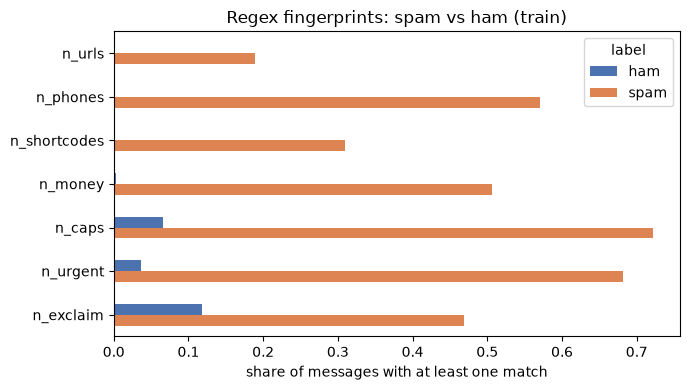

In [24]:
hits = (train[FINGERPRINTS] > 0).groupby(train["label"]).mean().T
ax = hits.plot.barh(color=[COLORS["ham"], COLORS["spam"]], figsize=(7, 4))
ax.set_xlabel("share of messages with at least one match")
ax.set_title("Regex fingerprints: spam vs ham (train)")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIG_DIR / "fingerprints_spam_vs_ham.png", dpi=150)
plt.show()

Top 15 unigrams and bigrams per class, counted on the processed `tokens` (FR-9).

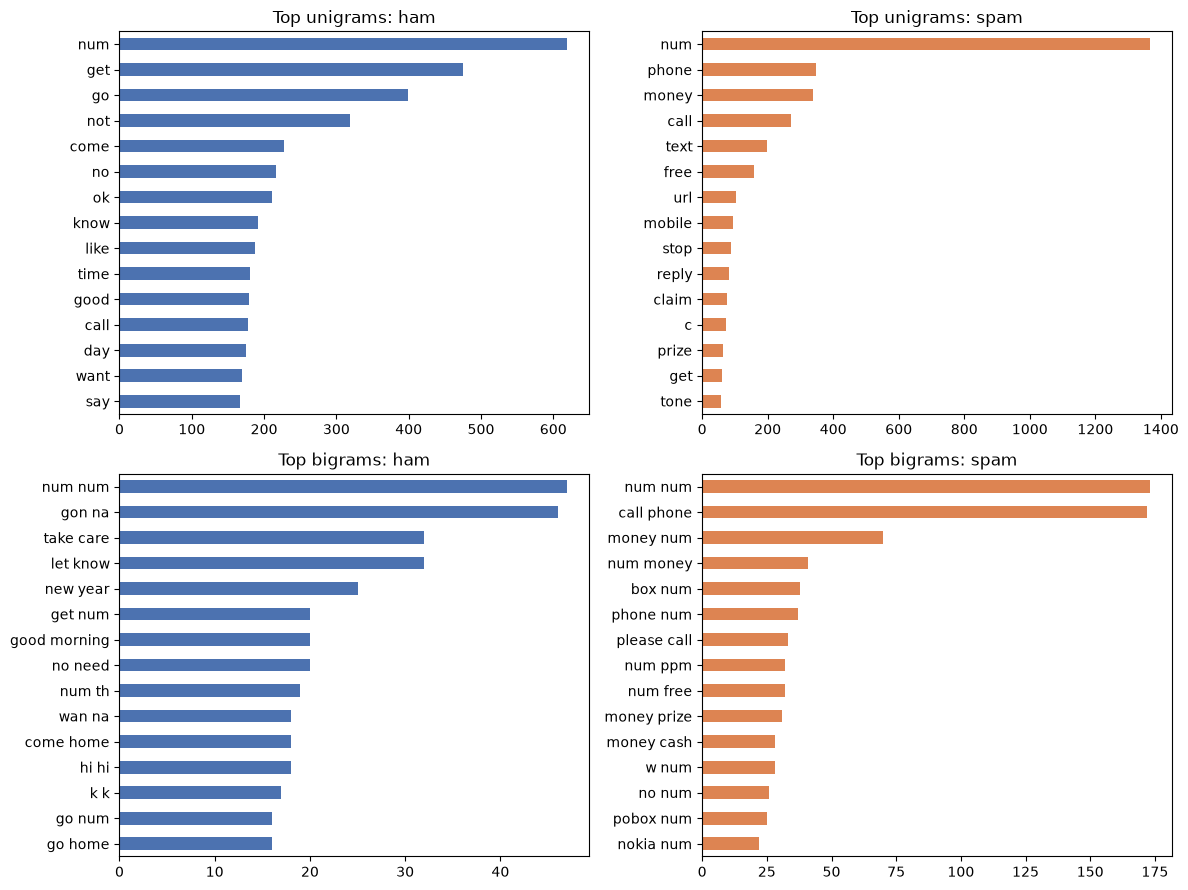

In [25]:
def top_ngrams(token_lists, n, k=15):
    """Most frequent n-grams across a collection of token lists."""
    counts = Counter(" ".join(g) for tokens in token_lists for g in ngrams(tokens, n))
    return pd.Series(dict(counts.most_common(k)))


fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, n in enumerate([1, 2]):
    for col, label in enumerate(["ham", "spam"]):
        top = top_ngrams(train.loc[train["label"] == label, "tokens"], n)
        ax = axes[row, col]
        top.iloc[::-1].plot.barh(ax=ax, color=COLORS[label])
        ax.set_title(f"Top {'unigrams' if n == 1 else 'bigrams'}: {label}")
plt.tight_layout()
plt.savefig(FIG_DIR / "top_ngrams.png", dpi=150)
plt.show()

Word clouds per class, before cleaning (raw lowercase words) and after the full pipeline (FR-10). Before: stopwords and filler dominate. After: content words and the `url`/`money`/`phone`/`num` placeholders stand out.

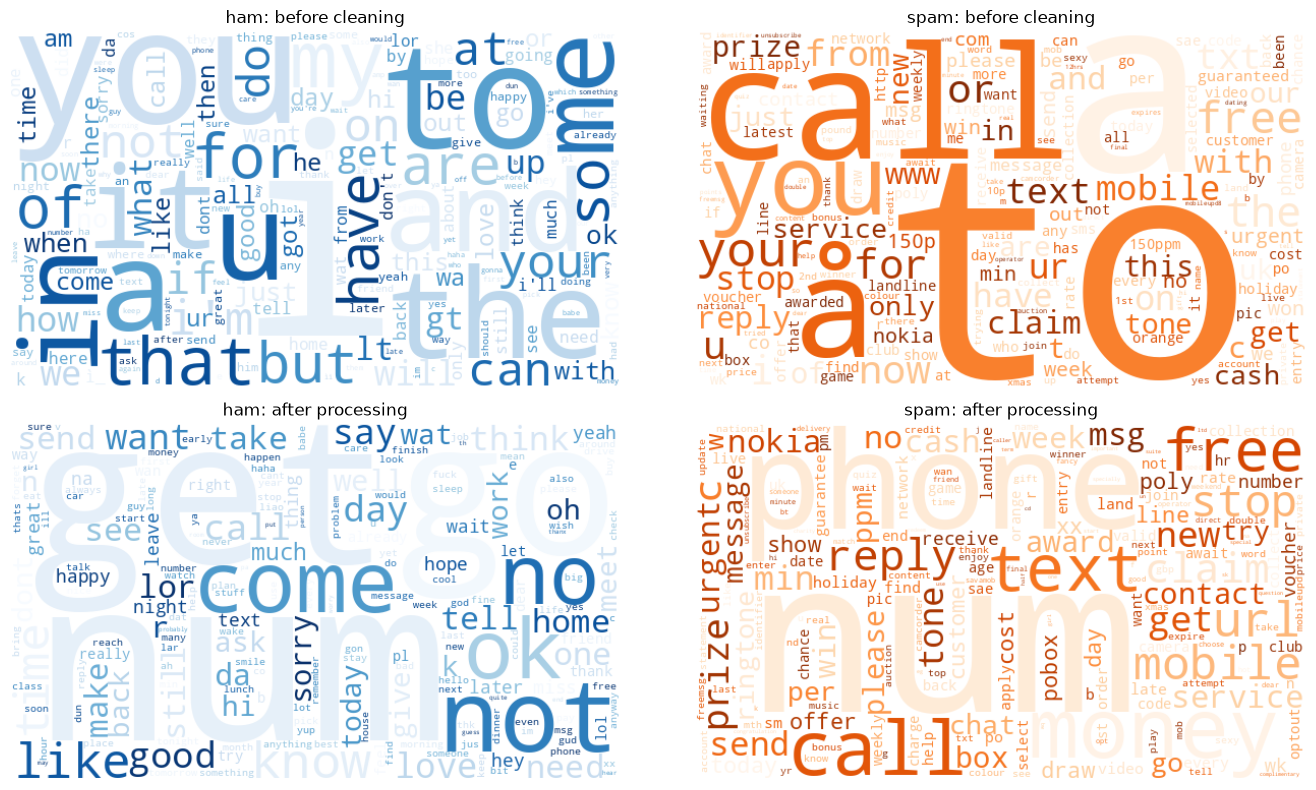

In [26]:
def cloud(text, colormap):
    return WordCloud(width=600, height=350, background_color="white", colormap=colormap,
                     collocations=False, stopwords=set(), random_state=RANDOM_STATE).generate(text)


fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for col, (label, cmap) in enumerate([("ham", "Blues"), ("spam", "Oranges")]):
    part = train[train["label"] == label]
    before = " ".join(part["text"].str.lower())
    after = " ".join(" ".join(t) for t in part["tokens"])
    for row, (stage, text) in enumerate([("before cleaning", before), ("after processing", after)]):
        axes[row, col].imshow(cloud(text, cmap), interpolation="bilinear")
        axes[row, col].set_title(f"{label}: {stage}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "wordclouds.png", dpi=150)
plt.show()

Most frequent words per class before vs after processing, as numbers (FR-10).

In [27]:
def top_words(texts, k=10):
    return [w for w, _ in Counter(w for t in texts for w in t).most_common(k)]


pd.DataFrame({
    f"{label} {stage}": top_words(col_fn(train[train['label'] == label]))
    for label in ["ham", "spam"]
    for stage, col_fn in [("before", lambda p: p["text"].str.lower().str.split()),
                          ("after", lambda p: p["tokens"])]
})

,ham before,ham after,spam before,spam after
0,i,num,to,num
1,you,get,a,phone
2,to,go,call,money
3,the,not,your,call
4,a,come,you,text
5,and,no,the,free
6,u,ok,for,url
7,in,know,or,mobile
8,my,like,free,stop
9,is,time,2,reply


## 9. Models and cross-validation (FR-11, FR-12)

Every model is an sklearn `Pipeline`. During cross-validation, each fold refits the whole pipeline (vocabulary, IDF weights, scaler, classifier) on its 4 training parts only, so nothing leaks from the validation part (NFR-5). The vectorizers take the processed tokens joined back into one string.

In [28]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

for part in (df, train, test):
    part["doc"] = part["tokens"].str.join(" ")

NUMERIC = FEATURE_NAMES + POS_FEATURES  # 10 regex/length features + 3 POS ratios
print(len(NUMERIC), "numeric features:", NUMERIC)

13 numeric features: ['n_urls', 'n_phones', 'n_shortcodes', 'n_money', 'n_caps', 'n_urgent', 'n_exclaim', 'n_chars', 'n_words', 'digit_ratio', 'pos_vb', 'pos_cd', 'pos_nnp']


Model 0 wrapped as an sklearn classifier: `fit` picks the `k` with the best spam F1 on the data it is given, so cross-validation re-tunes `k` inside every fold, exactly like the other models learn their weights.

In [29]:
class RegexRuleClassifier(ClassifierMixin, BaseEstimator):
    """Spam if at least k distinct regex fingerprints fire; k is tuned in fit()."""

    def fit(self, X, y):
        n = n_fingerprints(X)
        scores = {k: f1_score(y, (n >= k).astype(int)) for k in range(1, len(FINGERPRINTS) + 1)}
        self.k_ = max(scores, key=scores.get)
        self.classes_ = np.array([0, 1])
        return self

    def predict(self, X):
        return (n_fingerprints(X) >= self.k_).astype(int).to_numpy()

The candidates. Bag-of-words (raw counts) and TF-IDF are both used (FR-11); Model 3 scales its numeric features so they sit on a comparable range to the TF-IDF values.

In [30]:
def text_only(vectorizer):
    """Use only the processed-text column."""
    return ColumnTransformer([("text", vectorizer, "doc")])


def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2))


def make_model3():
    """Model 3: TF-IDF words + scaled regex/POS features -> Logistic Regression."""
    features = ColumnTransformer([("text", tfidf(), "doc"),
                                  ("numeric", StandardScaler(), NUMERIC)])
    return Pipeline([("features", features),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))])


models = {
    "Baseline (always ham)": DummyClassifier(strategy="constant", constant=0),
    "0: regex rules": RegexRuleClassifier(),
    "1: BoW + NB": Pipeline([("features", text_only(CountVectorizer(ngram_range=(1, 2)))), ("clf", MultinomialNB())]),
    "1b: TF-IDF + NB": Pipeline([("features", text_only(tfidf())), ("clf", MultinomialNB())]),
    "2: TF-IDF + SVM": Pipeline([("features", text_only(tfidf())), ("clf", LinearSVC())]),
    "3: TF-IDF + regex + POS, LogReg": make_model3(),
}

Stratified 5-fold cross-validation on the training set only; spam is the positive class.

In [31]:
import warnings
from sklearn.exceptions import UndefinedMetricWarning

# The always-ham baseline predicts no spam, so its precision is undefined (reported as 0).
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["precision", "recall", "f1", "accuracy"]

cv_rows = {}
for name, model in models.items():
    scores = cross_validate(model, train, train["y"], cv=cv, scoring=scoring)
    cv_rows[name] = {m: f"{scores['test_' + m].mean():.3f} ± {scores['test_' + m].std():.3f}" for m in scoring}

cv_results = pd.DataFrame(cv_rows).T
cv_results.columns = ["Precision", "Recall", "F1", "Accuracy"]
cv_results

,Precision,Recall,F1,Accuracy
Baseline (always ham),0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.875 ± 0.000
0: regex rules,0.888 ± 0.089,0.819 ± 0.080,0.844 ± 0.021,0.962 ± 0.006
1: BoW + NB,0.938 ± 0.027,0.928 ± 0.025,0.933 ± 0.015,0.983 ± 0.004
1b: TF-IDF + NB,1.000 ± 0.000,0.654 ± 0.039,0.790 ± 0.028,0.957 ± 0.005
2: TF-IDF + SVM,0.945 ± 0.017,0.928 ± 0.023,0.936 ± 0.006,0.984 ± 0.001
"3: TF-IDF + regex + POS, LogReg",0.919 ± 0.017,0.924 ± 0.034,0.921 ± 0.016,0.980 ± 0.004


**Reading the table.** The baseline shows why accuracy alone misleads: about 87% accuracy with zero spam caught. Naive Bayes works far better on raw counts than on TF-IDF, because it models how often words occur. Comparing Model 3 with the ablation run *without regex/POS features* (section 10) shows what the NLP features add.